# Pravni asistent za iznajmljivače: RAG nad hrvatskim zakonima o turizmu

U ovom projektu radim **RAG (Retrieval-Augmented Generation)** sustav koji odgovara na pitanja o hrvatskim zakonima vezanim uz turizam: iznajmljivanje u domaćinstvu, turističku pristojbu, ugostiteljsku djelatnost i slično.

Ideja je jednostavna: LLM sam po sebi ne zna točan sadržaj hrvatskih zakona i sklon je izmišljanju iznosa i rokova. Zato prvo **pretražujem zakone** i pronalazim relevantne članke, a onda ih **dajem LLM-u kao kontekst** i tražim da odgovori isključivo na temelju njih, uz navođenje izvora.



**Sve radi lokalno**(RTX 5070 Laptop, 8 GB VRAM), bez API ključeva i bez slanja podataka vani.

### Stack
| Dio | Alat |
|---|---|
| Učitavanje PDF-ova | `pypdf` |
| Embedding model | `BAAI/bge-m3` (višejezični, podržava hrvatski) preko `sentence-transformers` |
| Vektorska baza | `ChromaDB` (lokalno, na disku) |
| Leksička pretraga | BM25 (`rank-bm25`) |
| LLM | `gemma3:4b` preko **Ollame** (lokalno) |
| Demo | `Gradio` |





```bash
python -m venv .venv
.venv\Scripts\activate          # Windows  (Linux/Mac: source .venv/bin/activate)
pip install torch --index-url https://download.pytorch.org/whl/cu128
pip install -r requirements.txt
```

**Ollama:**  [ollama.com](https://ollama.com) 
```bash
ollama pull gemma3:4b
```
laptop ima 8 GB VRAM-a. Na grafičkoj istovremeno moraju biti i LLM i embedding model, pa sam uzeo model od 4B parametara (oko 3,3 GB). Veći `gemma3:12b` (oko 8 GB) ne bi stao cijeli na GPU i velikim dijelom bi radio na procesoru, puno sporije.

**Podaci:** sa [zakon.hr](https://www.zakon.hr) / [Narodnih novina](https://narodne-novine.nn.hr) spremljeno u `data/zakoni/` 

```
data/zakoni/
├── Zakon o pružanju usluga u turizmu.pdf
├── Zakon o ugostiteljskoj djelatnosti.pdf
├── Zakon o turističkoj pristojbi.pdf
└── Zakon o turističkim zajednicama i promicanju hrvatskog turizma.pdf
```

In [1]:
import re
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from pypdf import PdfReader
from sentence_transformers import SentenceTransformer
import chromadb
from rank_bm25 import BM25Okapi
import ollama

# Sve postavke držim na jednom mjestu da ih lako mijenjam
DATA_DIR = Path("data/zakoni")
CHROMA_DIR = Path("chroma_db")
EVAL_DIR = Path("eval")
EVAL_DIR.mkdir(exist_ok=True)

EMBED_MODEL = "BAAI/bge-m3"
LLM_MODEL = "gemma3:4b"
COLLECTION = "zakoni_turizam"

MAX_CHARS = 1500   # najveća duljina jednog chunka (znakovi)
OVERLAP = 200      # preklapanje kad dugačak članak režem na dijelove
TOP_K = 5          # koliko članaka dajem LLM-u kao kontekst

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Uređaj:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Uređaj: cuda
GPU: NVIDIA GeForce RTX 5070 Laptop GPU


In [2]:
# Provjeravam radi li Ollama i imam li skinut model
try:
    dostupni = [m.model for m in ollama.list().models]
    print("Ollama modeli:", dostupni)
    if not any(m.startswith(LLM_MODEL) for m in dostupni):
        print(f"⚠️ Nemam {LLM_MODEL}, pokrećem u terminalu: ollama pull {LLM_MODEL}")
except Exception as e:
    print("⚠️ Ollama ne radi. Pokrećem je (aplikacija ili `ollama serve`) pa ponavljam ćeliju.", e)

Ollama modeli: ['gemma3:4b']


## Učitavanje i čišćenje zakona

PDF-ovi zakona nisu čisti tekst. Imaju brojeve stranica, zaglavlja s web stranice i riječi rastavljene na kraju retka.

In [3]:
def ucitaj_pdf(path: Path) -> str:
    reader = PdfReader(path)
    return "\n".join(stranica.extract_text() or "" for stranica in reader.pages)


def ucitaj_dokument(path: Path) -> str:
    if path.suffix.lower() == ".pdf":
        return ucitaj_pdf(path)
    return path.read_text(encoding="utf-8")


def ocisti_tekst(tekst: str) -> str:
    tekst = tekst.replace("\u00ad", "")                      # meke crtice iz PDF-a
    tekst = tekst.replace("\r", "")
    linije = []
    for linija in tekst.split("\n"):
        l = linija.strip()
        if re.fullmatch(r"\d{1,3}", l):                      # samo broj stranice
            continue
        if "zakon.hr" in l.lower() or "narodne-novine" in l.lower():
            continue                                         # zaglavlja/podnožja s weba
        linije.append(l)
    tekst = "\n".join(linije)
    tekst = re.sub(r"(\w)-\n(\w)", r"\1\2", tekst)           # rastavljene riječi
    tekst = re.sub(r"[ \t]+", " ", tekst)
    tekst = re.sub(r"\n{3,}", "\n\n", tekst)
    return tekst.strip()


dokumenti = []
for path in sorted(DATA_DIR.glob("*")):
    if path.suffix.lower() not in {".pdf", ".txt"}:
        continue
    tekst = ocisti_tekst(ucitaj_dokument(path))
    dokumenti.append({"zakon": path.stem.replace("_", " "), "tekst": tekst})

assert dokumenti, f"Nema dokumenata u {DATA_DIR.resolve()}"

pd.DataFrame(
    [{"zakon": d["zakon"], "znakova": len(d["tekst"]), "riječi": len(d["tekst"].split())} for d in dokumenti]
)

,zakon,znakova,riječi
0,200728 ZTZ edit,76904,10288
1,211202 ZoUGD,116110,16719
2,ZAKON O PRUŽANJU USLUGA U TURIZMU pročišćeni 2025,205833,29922


In [4]:
# Na brzinu gledam kako izgleda očišćeni tekst
print(dokumenti[0]["tekst"][:1500])

MINISTARSTVO TURIZMA (neslužbeno pročišćeni tekst)

ZAKON
O TURISTIČKIM ZAJEDNICAMA I PROMICANJU HRVATSKOG TURIZMA
(„Narodne novine“ br. 52/19. i 42/20.)

GLAVA I.
TEMELJNE ODREDBE
Predmet Zakona
Članak 1.
Ovim se Zakonom, po modelu destinacijske menadžment organizacije, uređuje sustav
turističkih zajednica, ustrojstvo, zadaće i način rada turističkih zajednica te osnovna načela
njihova financiranja i gospodarenja.
Značenje pojmova
Članak 2.
Pojedini pojmovi u smislu ovoga Zakona imaju sljedeće značenje:
1. turistička destinacija (u daljnjem tekstu: destinacija) se definira kao tržišno i turistički
valorizirana prostorna cjelina koja predstavlja cilj turističkih putovanja i obuhvaća područje
jedne ili više jedinica lokalne ili područne (regionalne) samouprave
2. destinacijska menadžment organizacija se definira kao organizacija koja okuplja
dionike javnog, privatnog i civilnog sektora radi strateškog i operativnog upravljanja
destinacijom i ostvarivanja zajedničke, prethodno usuglašene





Zakoni imaju prirodnu strukturu: **članak je osnovna jedinica značenja**. Zato tekst dijelim po oznakama `Članak N.`, pa svaki chunk ima jasan izvor koji LLM može citirati. Samo članke duže od `MAX_CHARS` dodatno režem na dijelove s preklapanjem. Kad mogu, režem na kraju stavka ili rečenice.

Svakom chunku dodajem i zaglavlje (`Zakon X, članak N`) u tekst koji ide u embedding. Tako pretraga zna o kojem je zakonu riječ čak i kad sam članak to ne spominje.

In [5]:
# hvata "Članak 5." i "Članak 5.a" / "Članak 5 a" (članci dodani izmjenama zakona)
CLANAK_RE = re.compile(r"^\s*Članak\s+(\d+(?:\.?\s?[a-z])?)\.?\s*$", re.MULTILINE)


def podijeli_na_clanke(tekst: str):
    pogodci = list(CLANAK_RE.finditer(tekst))
    if not pogodci:
        return [("-", tekst)]
    clanci = []
    for i, m in enumerate(pogodci):
        kraj = pogodci[i + 1].start() if i + 1 < len(pogodci) else len(tekst)
        sadrzaj = tekst[m.end():kraj].strip()
        if sadrzaj:
            clanci.append((m.group(1).replace(" ", "").replace(".", ""), sadrzaj))
    return clanci


def razlomi_dugacak(tekst: str, max_chars=MAX_CHARS, overlap=OVERLAP):
    if len(tekst) <= max_chars:
        return [tekst]
    dijelovi, start = [], 0
    while start < len(tekst):
        kraj = min(start + max_chars, len(tekst))
        if kraj < len(tekst):
            # radije režem na kraju stavka, pa rečenice, nego usred riječi
            rez = tekst.rfind("\n", start + max_chars // 2, kraj)
            if rez == -1:
                rez = tekst.rfind(". ", start + max_chars // 2, kraj)
            if rez != -1:
                kraj = rez + 1
        dijelovi.append(tekst[start:kraj].strip())
        if kraj >= len(tekst):
            break
        start = kraj - overlap
    return dijelovi


chunkovi = []
for dok in dokumenti:
    for clanak, sadrzaj in podijeli_na_clanke(dok["tekst"]):
        for dio, tekst in enumerate(razlomi_dugacak(sadrzaj)):
            chunkovi.append({
                "id": f"c{len(chunkovi):05d}",   # redni broj, jer se brojevi članaka mogu ponavljati
                "zakon": dok["zakon"],
                "clanak": clanak,
                "dio": dio,
                "tekst": tekst,
                "tekst_za_embedding": f"{dok['zakon']}, članak {clanak}\n{tekst}",
            })

po_id = {c["id"]: c for c in chunkovi}
df_chunk = pd.DataFrame(chunkovi)
print(f"Ukupno chunkova: {len(chunkovi)}")
df_chunk.groupby("zakon").agg(clanaka=("clanak", "nunique"), chunkova=("id", "count"))

Ukupno chunkova: 475


,clanaka,chunkova
zakon,,
200728 ZTZ edit,81,105
211202 ZoUGD,68,134
ZAKON O PRUŽANJU USLUGA U TURIZMU pročišćeni 2025,133,236


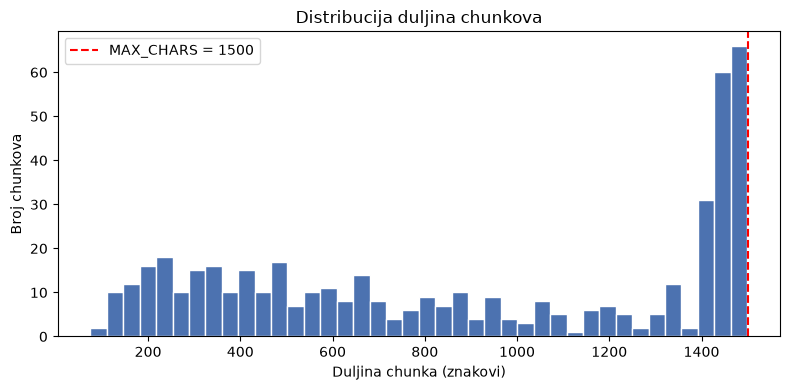

count     475.0
mean      891.0
std       491.0
min        75.0
25%       419.0
50%       869.0
75%      1432.0
max      1499.0
Name: tekst, dtype: float64


In [6]:
# Distribucija duljina: provjeravam ima li previše sitnih ili predugih chunkova
duljine = df_chunk["tekst"].str.len()
plt.figure(figsize=(8, 4))
plt.hist(duljine, bins=40, color="#4C72B0", edgecolor="white")
plt.axvline(MAX_CHARS, color="red", linestyle="--", label=f"MAX_CHARS = {MAX_CHARS}")
plt.xlabel("Duljina chunka (znakovi)")
plt.ylabel("Broj chunkova")
plt.title("Distribucija duljina chunkova")
plt.legend()
plt.tight_layout()
plt.show()

print(duljine.describe().round(0))

In [7]:
# Primjer jednog chunka
primjer = random.choice(chunkovi)
print(primjer["tekst_za_embedding"])

ZAKON O PRUŽANJU USLUGA U TURIZMU pročišćeni 2025, članak 61
(1) Pravna i fizička osoba iz članka 5. stavka 1. ovoga Zakona može organizirati putovanje (paketaranžman i izlet), sklapati ugovore o njemu i provoditi ih na plovilu koje je kategorizirano kao
plovni objekt nautičkog turizma te omogućavati povezani putni aranžman bez osnivanja turističke
agencije.

(2) Prodaja i rezerviranje (bukiranje) usluge iz stavka 1. ovoga članka može se obavljati:
– na plovnom objektu
– neposredno uz mjesto priveza plovnog objekta
– na za to predviđenom mjestu u objektu smještaja gostiju
– na prostoru koje odlukom određuje predstavničko tijelo jedinice lokalne samouprave ili lučka
uprava
– putem turističkih agencija
– na drugim prostorima uz suglasnost nositelja prava korištenja toga prostora.

(3) Na pružanje usluga iz stavka 1. ovoga članka na odgovarajući se način primjenjuju odredbe o
obvezama pružatelja usluga u turizmu iz članka 6. ovoga Zakona i odredbe o obvezama turističke
agencije iz članaka

## Embeddinzi i ChromaDB

**`BAAI/bge-m3`** To je višejezični model koji podržava hrvatski i prima duže tekstove (do 8192 tokena), a za upite ne traži posebne prefikse kao neki drugi modeli (npr. E5).

BERTić je odličan za hrvatski, ali je treniran kao klasifikacijski encoder, a ne za semantičku sličnost rečenica.

Embeddinge normaliziram, pa je kosinusna sličnost isto što i skalarni produkt. U Chromi zato postavljam `cosine` metriku.

In [8]:
embedder = SentenceTransformer(EMBED_MODEL, device=DEVICE)
if DEVICE == "cuda":
    embedder.half()   # fp16: upola manje VRAM-a, a ostatak ostaje LLM-u

t0 = time.time()
embeddinzi = embedder.encode(
    [c["tekst_za_embedding"] for c in chunkovi],
    batch_size=16,
    normalize_embeddings=True,
    show_progress_bar=True,
)
print(f"Embeddinzi: {embeddinzi.shape}, vrijeme: {time.time() - t0:.1f} s")

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/2.27G [00:00<?, ?B/s]

Batches:   0%|          | 0/30 [00:00<?, ?it/s]

Embeddinzi: (475, 1024), vrijeme: 4.9 s


In [9]:
client = chromadb.PersistentClient(path=str(CHROMA_DIR))

# Kolekciju svaki put radim ispočetka da ne ostanu stari chunkovi ako promijenim chunking
try:
    client.delete_collection(COLLECTION)
except Exception:
    pass
kolekcija = client.create_collection(COLLECTION, metadata={"hnsw:space": "cosine"})

BATCH = 1000
for i in range(0, len(chunkovi), BATCH):
    serija = chunkovi[i:i + BATCH]
    kolekcija.add(
        ids=[c["id"] for c in serija],
        embeddings=embeddinzi[i:i + BATCH].tolist(),
        documents=[c["tekst"] for c in serija],
        metadatas=[{"zakon": c["zakon"], "clanak": c["clanak"], "dio": c["dio"]} for c in serija],
    )

print("U kolekciji:", kolekcija.count(), "chunkova")

U kolekciji: 475 chunkova


##  dense vs. BM25 vs. hibridna

Uspoređujem tri načina pretrage:

- **Dense (vektorska)** traži po značenju. Pronalazi "smještaj kod kuće" i kad zakon kaže "ugostiteljske usluge u domaćinstvu".
- **BM25 (leksička)** traži po riječima. Dobra je za točne pojmove poput "paušal" ili "kategorizacija", ali hrvatski ima puno padeža: "pristojba", "pristojbe", "pristojbu" za BM25 su tri različite riječi. Kao grubu zamjenu za stemmer riječi skraćujem na **prvih 6 slova**. To je jednostavan trik koji se pokazao dosta efikasnim za slavenske jezike.
- **Hibridna** spaja obje liste pomoću **Reciprocal Rank Fusion (RRF)**. Gleda rang dokumenta u svakoj listi, a ne sirove skorove, jer skorovi BM25 i kosinusne sličnosti nisu na istoj skali.

In [10]:
def dense_pretraga(pitanje: str, k=TOP_K):
    q = embedder.encode([pitanje], normalize_embeddings=True)
    r = kolekcija.query(query_embeddings=q.tolist(), n_results=k)
    # Chroma vraća kosinusnu udaljenost, pa je pretvaram u sličnost
    return [(id_, 1 - d) for id_, d in zip(r["ids"][0], r["distances"][0])]


STOP_RIJECI = set(
    "i u na je se da za od do s sa o po ili a ako koji koja koje kojeg kojem kojoj "
    "te ne su biti bi može mora što kako li to taj ta ovaj ova ovo kao pri iz prema".split()
)


def tokeniziraj(tekst: str):
    return [r[:6] for r in re.findall(r"\w+", tekst.lower()) if r not in STOP_RIJECI and len(r) > 1]


bm25 = BM25Okapi([tokeniziraj(c["tekst_za_embedding"]) for c in chunkovi])
svi_id = [c["id"] for c in chunkovi]


def bm25_pretraga(pitanje: str, k=TOP_K):
    skorovi = bm25.get_scores(tokeniziraj(pitanje))
    top = np.argsort(skorovi)[::-1][:k]
    return [(svi_id[i], float(skorovi[i])) for i in top]


def hibridna_pretraga(pitanje: str, k=TOP_K, n_kandidata=20, k_rrf=60):
    rrf = {}
    for lista in (dense_pretraga(pitanje, n_kandidata), bm25_pretraga(pitanje, n_kandidata)):
        for rang, (id_, _) in enumerate(lista):
            rrf[id_] = rrf.get(id_, 0) + 1 / (k_rrf + rang + 1)
    return sorted(rrf.items(), key=lambda x: -x[1])[:k]


PRETRAGE = {"Dense": dense_pretraga, "BM25": bm25_pretraga, "Hibridna": hibridna_pretraga}

In [11]:
def prikazi_pogotke(pitanje: str, k=3):
    print(f"PITANJE: {pitanje}\n")
    for naziv, fn in PRETRAGE.items():
        print(f"── {naziv} ──")
        for id_, skor in fn(pitanje, k):
            c = po_id[id_]
            pocetak = c["tekst"][:120].replace("\n", " ")
            print(f"  {skor:7.3f} | {c['zakon']}, čl. {c['clanak']} | {pocetak}...")
        print()


prikazi_pogotke("Koliko iznosi turistička pristojba za iznajmljivače u domaćinstvu?")

PITANJE: Koliko iznosi turistička pristojba za iznajmljivače u domaćinstvu?

── Dense ──
    0.653 | 211202 ZoUGD, čl. 33 | Boravak više od 15 osoba u stanovima, apartmanima i kućama za odmor koje nisu članovi uže obitelji vlasnika stana, apart...
    0.625 | 211202 ZoUGD, čl. 30 | (1) Ugostiteljske usluge u domaćinstvu može pružati fizička osoba – građanin (u daljnjem tekstu: iznajmljivač).  (2) U s...
    0.625 | 211202 ZoUGD, čl. 49 | (1) Novčanom kaznom od 2000,00 do 5000,00 kuna kaznit će se za prekršaj iznajmljivač ako: 1. vidno ne istakne na ulazu u...

── BM25 ──
   11.090 | 211202 ZoUGD, čl. 33 | Boravak više od 15 osoba u stanovima, apartmanima i kućama za odmor koje nisu članovi uže obitelji vlasnika stana, apart...
    9.032 | ZAKON O PRUŽANJU USLUGA U TURIZMU pročišćeni 2025, čl. 12 | (1) Usluge turističke agencije su: 1. organiziranje, prodaja i provedba paket-aranžmana 2. omogućavanje kupnje putovanja...
    8.857 | 211202 ZoUGD, čl. 32 | (1) U pružanju ugostiteljskih us

In [12]:
prikazi_pogotke("Trebam li prijaviti goste koji kod mene spavaju?")

PITANJE: Trebam li prijaviti goste koji kod mene spavaju?

── Dense ──
    0.598 | 211202 ZoUGD, čl. 32 | (1) U pružanju ugostiteljskih usluga u domaćinstvu iznajmljivač je dužan: 1. vidno istaknuti na ulazu u objekt ili u nep...
    0.580 | 211202 ZoUGD, čl. 33 | Boravak više od 15 osoba u stanovima, apartmanima i kućama za odmor koje nisu članovi uže obitelji vlasnika stana, apart...
    0.570 | 211202 ZoUGD, čl. 32 | rigovora putem pošte, telefaksa ili elektroničke pošte, u objektu vidljivo istaknuti obavijest o načinu podnošenja pisan...

── BM25 ──
    7.027 | 211202 ZoUGD, čl. 47 | i napitak, ne pruži usluge u količinama i kakvoći sukladno normativima, nema normativ za vrijeme rada u ugostiteljskom o...
    6.961 | 211202 ZoUGD, čl. 10 | ti gostu 5. vidno istaknuti cijene usluga koje se nude na hrvatskom i najmanje jednom svjetskom jeziku, na način dostupa...
    4.958 | ZAKON O PRUŽANJU USLUGA U TURIZMU pročišćeni 2025, čl. 82 | (1) Ovlaštenja i poslovi turističkog predstavnika 

##  Generiranje odgovora s LLM-om

Pronađene članke slažem u kontekst i šaljem lokalnom LLM-u preko Ollame. U system promptu postavljam tri pravila:
1. odgovaraj **samo** na temelju priloženih članaka,
2. ako odgovora nema, reci da ga ne možeš pronaći (umjesto da izmišljaš),
3. uvijek navedi izvor u obliku *(Zakon, članak N)*.



In [13]:
SYSTEM_PROMPT = '''Ti si asistent koji pomaže iznajmljivačima i ugostiteljima u Hrvatskoj razumjeti zakone iz područja turizma.

Pravila:
- Odgovaraj ISKLJUČIVO na temelju priloženih članaka zakona.
- Ako odgovor nije u priloženim člancima, odgovori točno: "Ne mogu pronaći odgovor u dostupnim zakonima."
- Ne izmišljaj iznose, rokove, kazne ni brojeve članaka.
- Na kraju svake tvrdnje navedi izvor u obliku (Naziv zakona, članak N).
- Odgovaraj na hrvatskom jeziku, kratko i jasno, razumljivo osobi koja nije pravnik.'''


def formatiraj_kontekst(pogodci):
    blokovi = []
    for id_, _ in pogodci:
        c = po_id[id_]
        blokovi.append(f"[{c['zakon']}, članak {c['clanak']}]\n{c['tekst']}")
    return "\n\n---\n\n".join(blokovi)


def pozovi_llm(poruke, temperatura=0.1):
    odgovor = ollama.chat(model=LLM_MODEL, messages=poruke, options={"temperature": temperatura})
    return odgovor["message"]["content"].strip()


def pitaj(pitanje: str, k=TOP_K, pretraga=hibridna_pretraga):
    t0 = time.time()
    pogodci = pretraga(pitanje, k)
    t_pretraga = time.time() - t0

    poruke = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f"ČLANCI ZAKONA:\n\n{formatiraj_kontekst(pogodci)}\n\nPITANJE: {pitanje}"},
    ]
    odgovor = pozovi_llm(poruke)
    return {
        "odgovor": odgovor,
        "izvori": list(dict.fromkeys((po_id[i]["zakon"], po_id[i]["clanak"]) for i, _ in pogodci)),
        "t_pretraga": t_pretraga,
        "t_ukupno": time.time() - t0,
    }


def ispisi(r):
    print(r["odgovor"])
    print("\nPretraženi članci:")
    for zakon, clanak in r["izvori"]:
        print(f"  - {zakon}, članak {clanak}")
    print(f"\n⏱ pretraga {r['t_pretraga']*1000:.0f} ms | ukupno {r['t_ukupno']:.1f} s")

In [14]:
ispisi(pitaj("Koliko iznosi turistička pristojba za iznajmljivače u domaćinstvu i do kada se plaća?"))

Turistička pristojba se plaća po svakom ostvarenom noćenju u punom iznosu, sukladno posebnom propisu kojim se propisuje obveza plaćanja boravišne pristojbe. Konkretni iznos i rok plaćanja se propisuju posebnim propisima, a ne u ovim člancima. (211202 ZoUGD, članak 33)

Pretraženi članci:
  - 211202 ZoUGD, članak 33
  - 211202 ZoUGD, članak 32
  - 211202 ZoUGD, članak 30
  - 211202 ZoUGD, članak 49
  - 211202 ZoUGD, članak 48

⏱ pretraga 66 ms | ukupno 46.8 s


In [15]:
ispisi(pitaj("Koliko najviše kreveta smijem imati ako iznajmljujem u domaćinstvu?"))

U smislu članka 30. stavka 3. točke 1. Zakona o turizmu (211202 ZoUGD), iznajmljivač može iznajmljivati smještaj u sobi, apartmanu i kući za odmor do najviše deset soba, odnosno 20 kreveta, u koji broj se ne ubrajaju pomoćni kreveti. (211202 ZoUGD, članak 30)

Pretraženi članci:
  - 211202 ZoUGD, članak 30
  - 211202 ZoUGD, članak 48
  - 211202 ZoUGD, članak 34
  - 211202 ZoUGD, članak 39
  - ZAKON O PRUŽANJU USLUGA U TURIZMU pročišćeni 2025, članak 94

⏱ pretraga 24 ms | ukupno 2.0 s


In [16]:
# Pitanje izvan domene: model bi trebao odbiti umjesto da odgovara
ispisi(pitaj("Tko je osvojio Svjetsko prvenstvo u nogometu 2018.?"))

Ne mogu pronaći odgovor u dostupnim zakonima.

Pretraženi članci:
  - ZAKON O PRUŽANJU USLUGA U TURIZMU pročišćeni 2025, članak 7
  - ZAKON O PRUŽANJU USLUGA U TURIZMU pročišćeni 2025, članak 128
  - 211202 ZoUGD, članak 4
  - ZAKON O PRUŽANJU USLUGA U TURIZMU pročišćeni 2025, članak 32

⏱ pretraga 36 ms | ukupno 0.9 s


### Usporedba: isti LLM bez RAG-a

Da vidim zašto RAG uopće treba, isto pitanje postavljam LLM-u **bez konteksta**. Očekujem odgovor koji zvuči uvjerljivo, ali s izmišljenim ili zastarjelim iznosima i bez pravog izvora.

In [17]:
pitanje = "Koliko iznosi turistička pristojba za iznajmljivače u domaćinstvu i do kada se plaća?"
bez_rag = pozovi_llm([
    {"role": "system", "content": "Odgovaraj na hrvatskom jeziku, kratko i jasno."},
    {"role": "user", "content": pitanje},
])
print("BEZ RAG-a:\n", bez_rag)

BEZ RAG-a:
 Turistička pristojba iznosi 3€ po osobi i danu boravka. Plaća se plaća redovito tijekom boravka.


## Evaluacija

Evaluaciju u tri dijela:

**Pretraga (sintetička pitanja).** Nasumično biram članke i tražim od LLM-a da za svaki napiše pitanje na koje taj članak odgovara. Onda mjerim pronalazi li pretraga taj članak:
- **Hit@k**: je li pravi članak među prvih k rezultata,
- **MRR** (Mean Reciprocal Rank): prosjek od 1/rang pravog članka, pa nagrađuje kad je pravi članak visoko.

**Ručna pitanja.**  Sintetička pitanja su često preslična tekstu članka i time idu na ruku BM25. Zato imam i set pitanja koja sam sam napisao, onako kako bi ih stvarno postavio iznajmljivač.

**Kvaliteta odgovora.** LLM kao sudac ocjenjuje je li odgovor vjeran članku. Uz to provjeravam odbija li model pitanja izvan domene.

### Sintetička pitanja za pretragu

In [18]:
N_EVAL = 60
EVAL_PATH = EVAL_DIR / "sinteticka_pitanja.json"

PROMPT_GEN = '''Pročitaj sljedeći članak hrvatskog zakona i napiši JEDNO pitanje koje bi iznajmljivač ili ugostitelj mogao postaviti, a na koje ovaj članak daje odgovor.
Pitanje NE SMIJE spominjati broj članka ni naziv zakona i treba biti napisano svakodnevnim jezikom.
Vrati SAMO pitanje, bez ikakvog dodatnog teksta.

ČLANAK:
{tekst}'''

# Pitanja generiram jednom i spremam, da evaluacija bude ponovljiva i da ne čekam LLM svaki put
if EVAL_PATH.exists():
    sinteticka = json.loads(EVAL_PATH.read_text(encoding="utf-8"))
    print(f"Učitao {len(sinteticka)} pitanja iz {EVAL_PATH}")
else:
    kandidati = [c for c in chunkovi if len(c["tekst"]) > 300]
    uzorak = random.sample(kandidati, min(N_EVAL, len(kandidati)))
    sinteticka = []
    for i, c in enumerate(uzorak, 1):
        p = pozovi_llm([{"role": "user", "content": PROMPT_GEN.format(tekst=c["tekst"])}], temperatura=0.3)
        p = p.strip().strip('"').split("\n")[0]
        sinteticka.append({"pitanje": p, "zakon": c["zakon"], "clanak": c["clanak"], "id": c["id"]})
        print(f"{i:2d}/{len(uzorak)}  {p}")
    EVAL_PATH.write_text(json.dumps(sinteticka, ensure_ascii=False, indent=2), encoding="utf-8")

pd.DataFrame(sinteticka).head(10)

 1/60  Što se mora napraviti ako turistička zajednica donese program rada koji ne odgovara općim smjerovima i uputama?
 2/60  Što se mora dogoditi da se moja odluka u turističkom vijeću smatra valjnom?
 3/60  Što se događa ako se cijena aranžmana naglo poveća i ne dogovori se unaprijed?
 4/60  Može li mi netko reći koliko ljudi smijem služiti istodobno ako sam u mom gospodarstvu i nudim i jelo i piće koje sam sam napravio?
 5/60  Može li mi reći gdje mogu postaviti svoj šator ako dolazim na manifestaciju?
 6/60  Što se događa s ugostiteljem ako se izmijeni pravila i rokove za kategorizaciju, a još uvijek postoje posebne okolnosti koje su utjecale na njegovu prethodnu kategorizaciju?
 7/60  Što ako se u upravnom postupku dokaže da je turistička zajednica redovito neizvršavala odluke skupštine?
 8/60  Što se sada treba koristiti za klasifikaciju smještajnih objekata u turističke cjeline?
 9/60  Što ako mi je Turističko vijeće dodijelilo zadatak da organiziram prezentacije u županijskim g

,pitanje,zakon,clanak,id
0,Što se mora napraviti ako turistička zajednica...,200728 ZTZ edit,55,c00070
1,Što se mora dogoditi da se moja odluka u turis...,200728 ZTZ edit,17,c00019
2,Što se događa ako se cijena aranžmana naglo po...,ZAKON O PRUŽANJU USLUGA U TURIZMU pročišćeni 2025,16,c00456
3,Može li mi netko reći koliko ljudi smijem služ...,211202 ZoUGD,39,c00167
4,Može li mi reći gdje mogu postaviti svoj šator...,211202 ZoUGD,29,c00151
5,Što se događa s ugostiteljem ako se izmijeni p...,211202 ZoUGD,22,c00139
6,Što ako se u upravnom postupku dokaže da je tu...,200728 ZTZ edit,66,c00084
7,Što se sada treba koristiti za klasifikaciju s...,ZAKON O PRUŽANJU USLUGA U TURIZMU pročišćeni 2025,15,c00454
8,Što ako mi je Turističko vijeće dodijelilo zad...,200728 ZTZ edit,51,c00065
9,Kada morim poslati obavijest Ministarstvu o po...,ZAKON O PRUŽANJU USLUGA U TURIZMU pročišćeni 2025,110,c00408


In [19]:
def evaluiraj_pretragu(pitanja, ks=(1, 3, 5)):
    rezultati = []
    max_k = max(ks)
    for naziv, fn in PRETRAGE.items():
        hitovi = {k: 0 for k in ks}
        rr, vremena = [], []
        for p in pitanja:
            t0 = time.time()
            pogodci = fn(p["pitanje"], max_k)
            vremena.append(time.time() - t0)
            # pogodak = isti zakon i isti članak (članak može biti razlomljen na više dijelova)
            tocni = [(po_id[i]["zakon"], po_id[i]["clanak"]) == (p["zakon"], p["clanak"]) for i, _ in pogodci]
            rang = tocni.index(True) + 1 if any(tocni) else None
            for k in ks:
                hitovi[k] += int(rang is not None and rang <= k)
            rr.append(1 / rang if rang else 0)
        red = {"Metoda": naziv}
        red.update({f"Hit@{k}": hitovi[k] / len(pitanja) for k in ks})
        red["MRR"] = np.mean(rr)
        red["ms/upit"] = np.mean(vremena) * 1000
        rezultati.append(red)
    return pd.DataFrame(rezultati).set_index("Metoda")


rez_sint = evaluiraj_pretragu(sinteticka)
rez_sint.round(3)

,Hit@1,Hit@3,Hit@5,MRR,ms/upit
Metoda,,,,,
Dense,0.433,0.667,0.750,0.558,26.110
BM25,0.350,0.517,0.567,0.437,0.320
Hibridna,0.500,0.700,0.800,0.612,13.159


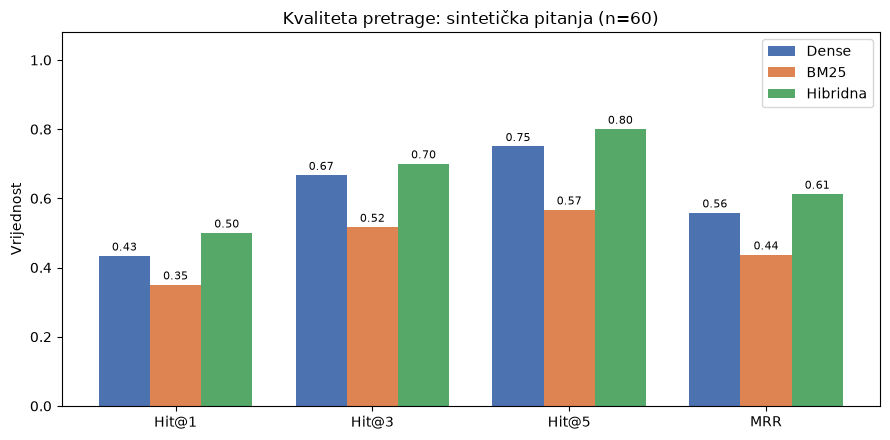

In [20]:
def nacrtaj_rezultate(df, naslov):
    metrike = ["Hit@1", "Hit@3", "Hit@5", "MRR"]
    x = np.arange(len(metrike))
    sirina = 0.26
    boje = {"Dense": "#4C72B0", "BM25": "#DD8452", "Hibridna": "#55A868"}
    plt.figure(figsize=(9, 4.5))
    for i, metoda in enumerate(df.index):
        vrijednosti = df.loc[metoda, metrike].values
        stupci = plt.bar(x + (i - 1) * sirina, vrijednosti, sirina, label=metoda, color=boje.get(metoda))
        plt.bar_label(stupci, fmt="%.2f", fontsize=8, padding=2)
    plt.xticks(x, metrike)
    plt.ylim(0, 1.08)
    plt.ylabel("Vrijednost")
    plt.title(naslov)
    plt.legend()
    plt.tight_layout()
    plt.show()


nacrtaj_rezultate(rez_sint, f"Kvaliteta pretrage: sintetička pitanja (n={len(sinteticka)})")

### Ručno napisana pitanja

Ručna pitanja  `eval/rucna_pitanja.json`.  Format:
```json
[
  {"pitanje": "Moram li plaćati paušal ako iznajmljujem samo ljeti?", "zakon": "Zakon o turističkoj pristojbi", "clanak": "…"}
]
```

Zakon o pružanju usluga u turizmu  →  ZAKON O PRUŽANJU USLUGA U TURIZMU pročišćeni 2025
Zakon o turističkim zajednicama i promicanju hrvatskog turizma  →  200728 ZTZ edit
Zakon o turističkoj pristojbi  →  ⚠️ NIJE PRONAĐEN
Zakon o ugostiteljskoj djelatnosti  →  211202 ZoUGD


,Hit@1,Hit@3,Hit@5,MRR,ms/upit
Metoda,,,,,
Dense,0.364,0.636,0.682,0.496,14.928
BM25,0.182,0.455,0.545,0.316,0.265
Hibridna,0.364,0.545,0.591,0.466,11.450


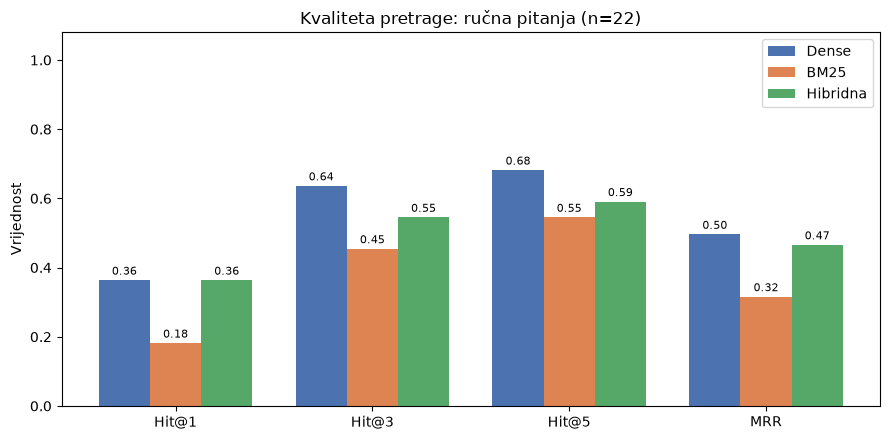

In [27]:
RUCNA_PATH = EVAL_DIR / "rucnapitanja.json"

# Imena PDF-ova ne moraju odgovarati nazivima zakona u pitanjima,
# pa svaki dokument prepoznajem po naslovu zakona na početku teksta
def mapiraj_zakone(nazivi):
    mapa = {}
    for d in dokumenti:
        tekst = re.sub(r"\s+", " ", d["tekst"][:5000]).lower()
        pozicije = {n: tekst.find(n.lower()) for n in nazivi if tekst.find(n.lower()) != -1}
        if pozicije:
            mapa[min(pozicije, key=pozicije.get)] = d["zakon"]
    return mapa

if RUCNA_PATH.exists():
    rucna = json.loads(RUCNA_PATH.read_text(encoding="utf-8"))
    mapa = mapiraj_zakone({p["zakon"] for p in rucna})
    for naziv in sorted({p["zakon"] for p in rucna}):
        print(f"{naziv}  →  {mapa.get(naziv, '⚠️ NIJE PRONAĐEN')}")
    for p in rucna:
        p["zakon"] = mapa.get(p["zakon"], p["zakon"])

    rez_rucna = evaluiraj_pretragu(rucna)
    display(rez_rucna.round(3))
    nacrtaj_rezultate(rez_rucna, f"Kvaliteta pretrage: ručna pitanja (n={len(rucna)})")
else:
    print(f"Nema {RUCNA_PATH}, preskačem ručnu evaluaciju.")

### Kvaliteta odgovora (LLM kao sudac)

Za dio sintetičkih pitanja generiram odgovor kroz cijeli RAG pipeline. Onda drugi poziv LLM-a uspoređuje odgovor s izvornim člankom i daje ocjenu: **TOČNO / DJELOMIČNO / NETOČNO**.

Ograničenje: isti model ocjenjuje sam sebe, pa je ocjena vjerojatno blaža nego što bi bila od čovjeka ili jačeg modela. Svejedno je korisna za relativnu usporedbu

In [22]:
N_SUDAC = 20

PROMPT_SUDAC = '''Ocjenjuješ odgovor AI asistenta na pitanje o hrvatskom zakonu.

IZVORNI ČLANAK (točan odgovor se nalazi ovdje):
{clanak}

PITANJE: {pitanje}

ODGOVOR ASISTENTA:
{odgovor}

Je li odgovor asistenta točan i u skladu s izvornim člankom?
Odgovori JEDNOM riječju: TOČNO, DJELOMIČNO ili NETOČNO.'''

ocjene = []
for p in sinteticka[:N_SUDAC]:
    r = pitaj(p["pitanje"])
    clanak = "\n".join(c["tekst"] for c in chunkovi if (c["zakon"], c["clanak"]) == (p["zakon"], p["clanak"]))
    sud = pozovi_llm([{"role": "user", "content": PROMPT_SUDAC.format(
        clanak=clanak, pitanje=p["pitanje"], odgovor=r["odgovor"])}], temperatura=0)
    sud = next((o for o in ["DJELOMIČNO", "NETOČNO", "TOČNO"] if o in sud.upper()), "NEPOZNATO")
    ocjene.append({"pitanje": p["pitanje"], "ocjena": sud, "odgovor": r["odgovor"], "s": round(r["t_ukupno"], 1)})

df_ocjene = pd.DataFrame(ocjene)
print(df_ocjene["ocjena"].value_counts(normalize=True).round(2))
print(f"\nProsječno vrijeme odgovora: {df_ocjene['s'].mean():.1f} s")
df_ocjene

ocjena
TOČNO         0.75
NETOČNO       0.20
DJELOMIČNO    0.05
Name: proportion, dtype: float64

Prosječno vrijeme odgovora: 3.3 s


,pitanje,ocjena,odgovor,s
0,Što se mora napraviti ako turistička zajednica...,TOČNO,Ako turistička zajednica donese program rada k...,2.3
1,Što se mora dogoditi da se moja odluka u turis...,TOČNO,"Na temelju priloženih članaka zakona, da bi se...",3.1
2,Što se događa ako se cijena aranžmana naglo po...,TOČNO,Ako se cijena aranžmana naglo poveća i ne dogo...,2.9
3,Može li mi netko reći koliko ljudi smijem služ...,TOČNO,"Na temelju priloženih članaka zakona, slijede ...",7.4
4,Može li mi reći gdje mogu postaviti svoj šator...,DJELOMIČNO,"Na temelju priloženih članaka zakona, možete p...",4.1
5,Što se događa s ugostiteljem ako se izmijeni p...,TOČNO,"S obzirom na priložene članke zakona, ako se i...",5.6
6,Što ako se u upravnom postupku dokaže da je tu...,TOČNO,Ako se u upravnom postupku dokaže da je turist...,3.2
7,Što se sada treba koristiti za klasifikaciju s...,NETOČNO,Za klasifikaciju smještajnih objekata u turist...,2.4
8,Što ako mi je Turističko vijeće dodijelilo zad...,TOČNO,Prezentacije koje su vam dodijeljene od strane...,1.8
9,Kada morim poslati obavijest Ministarstvu o po...,TOČNO,Obavijest o početku pružanja usluga morate pos...,2.2


In [23]:
# Pitanja izvan domene: dobar sustav treba odbiti odgovor, a ne izmišljati
IZVAN_DOMENE = [
    "Koji je glavni grad Australije?",
    "Kako se radi pašticada?",
    "Kolika je kazna za prebrzu vožnju na autocesti?",
    "Tko je napisao roman Na Drini ćuprija?",
    "Koliko iznosi porez na dobit za velika poduzeća?",
]

ODBIJANJE = "ne mogu pronaći odgovor"
odbijeni = 0
for p in IZVAN_DOMENE:
    r = pitaj(p)
    odbio = ODBIJANJE in r["odgovor"].lower()
    odbijeni += odbio
    print(f"{'✅' if odbio else '❌'} {p}\n   → {r['odgovor'][:150]}\n")

print(f"Stopa odbijanja izvan domene: {odbijeni}/{len(IZVAN_DOMENE)}")

✅ Koji je glavni grad Australije?
   → Ne mogu pronaći odgovor u dostupnim zakonima.

✅ Kako se radi pašticada?
   → Ne mogu pronaći odgovor u dostupnim zakonima.

✅ Kolika je kazna za prebrzu vožnju na autocesti?
   → Ne mogu pronaći odgovor u dostupnim zakonima. Zakoni koje ste mi dostavili se bave pružanjem usluga u turizmu, a ne prekršajima cestovnog prometa. Za 

✅ Tko je napisao roman Na Drini ćuprija?
   → Ne mogu pronaći odgovor u dostupnim zakonima.

✅ Koliko iznosi porez na dobit za velika poduzeća?
   → U dostupnim zakonima ne mogu pronaći odgovor na pitanje o iznosu poreza na dobit za velika poduzeća. (ZAKON O PRUŽANJU USLUGA U TURIZMU pročišćeni 202

Stopa odbijanja izvan domene: 5/5


## Chat demo

Na kraju radim jednostavno chat sučelje u Gradiju, da sustav mogu pokazati nekome tko ne gleda kod.

In [24]:
import gradio as gr


def chat_fn(poruka, povijest):
    r = pitaj(poruka)
    izvori = "\n".join(f"- {z}, članak {c}" for z, c in r["izvori"])
    return f"{r['odgovor']}\n\n---\n**Pretraženi članci:**\n{izvori}"


demo = gr.ChatInterface(
    fn=chat_fn,
    title="⚖️ Pravni asistent za iznajmljivače",
    description="Pitaj o hrvatskim zakonima iz turizma. Odgovori se temelje isključivo na tekstu zakona i nisu pravni savjet.",
    examples=[
        "Koliko iznosi turistička pristojba za iznajmljivače u domaćinstvu?",
        "Koliko najviše kreveta smijem imati u domaćinstvu?",
        "Moram li prijaviti goste i u kojem roku?",
    ],
)
demo.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


## Zaključci



### Rezultati



| Metoda | Sintetička (n=60) Hit@5 | Sintetička MRR | Ručna (n=22) Hit@5 | Ručna MRR |
|---|---|---|---|---|
| Dense | 0.75 | 0.56 | **0.68** | **0.50** |
| BM25 | 0.57 | 0.44 | 0.55 | 0.32 |
| Hibridna | **0.80** | **0.61** | 0.59 | 0.47 |

- Na sintetičkim pitanjima najbolja je **hibridna pretraga**: spajanje vektorske i leksičke pretrage pobjeđuje svaku metodu zasebno.
- Na ručnim pitanjima, napisanima svakodnevnim jezikom, najbolja je **čista vektorska (dense) pretraga**. Iznajmljivač pita "koliko soba smijem imati", a zakon govori o "smještaju u sobi, apartmanu i kući za odmor do najviše deset soba". Riječi se slabo poklapaju, pa pretraga po značenju radi bolje.
- **BM25 je najslabiji u oba slučaja**, a najviše pada na ručnim pitanjima (Hit@1 samo 0.18). 
- Svi rezultati su niži na ručnim pitanjima. To potvrđuje da **sintetička evaluacija precjenjuje kvalitetu pretrage**: pitanja koja LLM generira iz članka preslična su tekstu tog članka.

**Kvaliteta odgovora.** Na 20 pitanja LLM-sudac je ocijenio 75 % odgovora kao točne, 5 % kao djelomično točne i 20 % kao netočne. Pretraga traje 20–70 ms, a cijeli odgovor 1–7 s na RTX 5070 Laptop GPU. Prvi poziv traje dulje (~45 s) jer se model tek učitava u memoriju.

**Odbijanje pitanja izvan domene.** Sustav je odbio odgovoriti na **5/5** pitanja koja nemaju veze sa zakonima (glavni grad Australije, recept za pašticadu...) umjesto da izmišlja. Nije izmislio broj, što je upravo cilj RAG-a.


- **Evaluacija je mijenjala odluke.** Da sam gledao samo sintetička pitanja, zaključio bih da je hibridna pretraga najbolja. Ručni set pokazao je da je za stvarne korisnike bolja čista vektorska pretraga.
- **Chunking po člancima** je dobar izbor za zakone: svaki chunk ima jasan izvor koji se može citirati. Distribucija duljina pokazuje da je dio članaka dug pa se dijeli na više dijelova (vrh kod 1500 znakova).
- **Mali lokalni model (gemma3:4b)** dovoljno dobro odgovara na hrvatskom kad dobije pravi kontekst, ali je slabiji u generiranju evaluacijskih pitanja: neka imaju tipfelere ili su nejasna 

### Ograničenja
- **Zakoni se mijenjaju.** Sustav zna samo ono što je u `data/zakoni/`, a dio dokumenata nije najnovija verzija. Iznosi pristojbi su u posebnim uredbama i odlukama, a ne u zakonima.
- **Izvori se citiraju imenom datoteke.** Kad se PDF zove npr. "211202 ZoUGD", model ponekad pogrešno imenuje zakon u odgovoru.
- **LLM kao sudac ocjenjuje sam sebe**
- **Ručni evaluacijski set je mali** (22 pitanja).


